# Visualisasi Eksperimen Latent

RankUp dengan augmentasi weak/strong di **ruang latent** TabM, dibandingkan dengan augmentasi di input.
Data: `../hasil/results.jsonl` (3 dataset × 3 label × 3 seed per konfigurasi). Konfigurasi dipilih dari **validation**.

In [1]:
import os, sys
if not os.path.exists('ringkas.py'):  # REPL Zed bisa memulai kernel dari root folder yang dibuka
    os.chdir(next(p for p in ('kode', 'Experiment Latent/kode') if os.path.exists(p)))
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle
from ringkas import HASIL, load

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
                     'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb'})
INK, MUTED = '#0b0b0b', '#8a8984'
GROUP_COLOR = {'Tanpa RankUp': '#b5b4ad', 'RankUp tanpa aug': '#52514e', 'Input': '#eb6834',
               'Input + latent': '#eda100', 'Latent': '#2a78d6'}

def group(name):
    if name == 'supervised': return 'Tanpa RankUp'
    if name == 'rankup_noaug': return 'RankUp tanpa aug'
    for prefix, label in (('input_', 'Input'), ('both_', 'Input + latent'), ('latent_', 'Latent'),
                          ):
        if name.startswith(prefix): return label

df = load()
df = df[~df['name'].str.startswith(('angular', 'matched_'))].copy()  # angular ditunda dulu
df['group'] = df['name'].map(group)
keys = ['dataset', 'label', 'seed']

def mean_rank(frame):
    frame = frame[frame.groupby(keys)['name'].transform('count') == frame['name'].nunique()].copy()
    frame['rank'] = frame.groupby(keys)['val_good'].rank(ascending=False)
    return frame.groupby('name')['rank'].mean()

ranks = mean_rank(df)
print(f"{len(df)} run, {df['name'].nunique()} konfigurasi")

540 run, 20 konfigurasi


## Hasil utama: 4 augmentasi, di input vs di latent

Skor test asli (rata-rata 3 seed), satu gambar per dataset dan satu panel per persentase label.
Oranye = augmentasi di data input (cara RankUp asli), biru = augmentasi di latent (usulan).

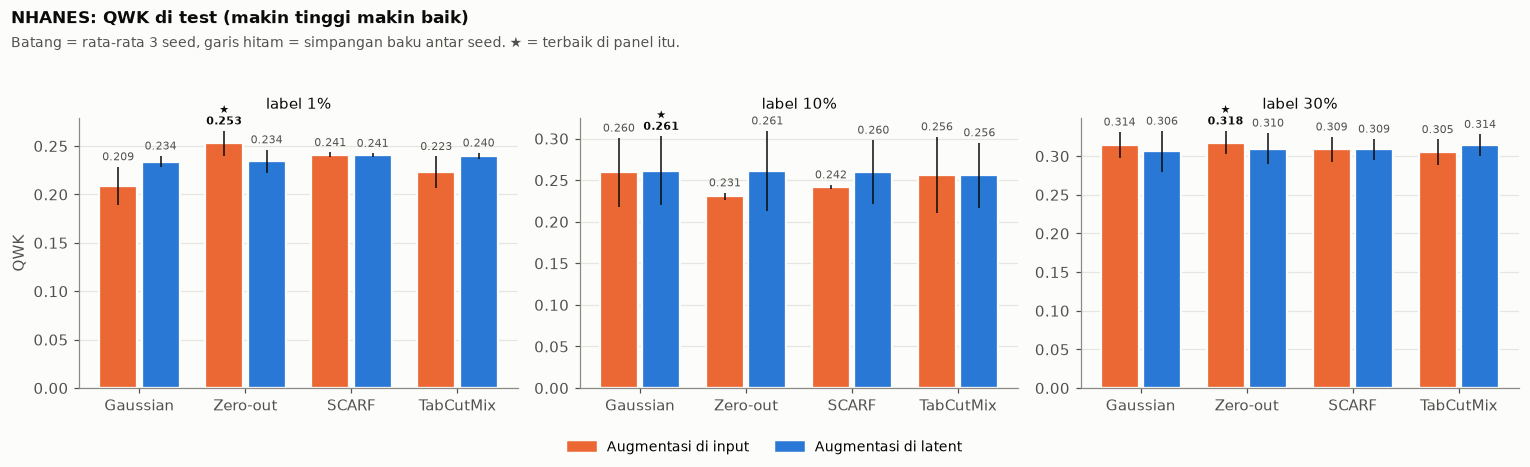

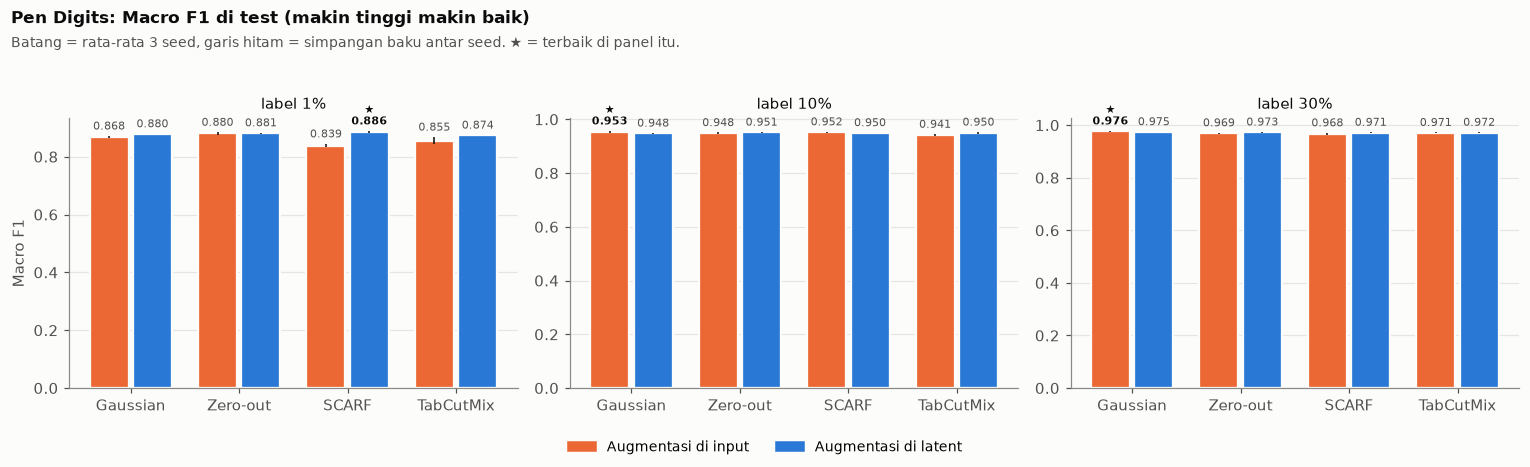

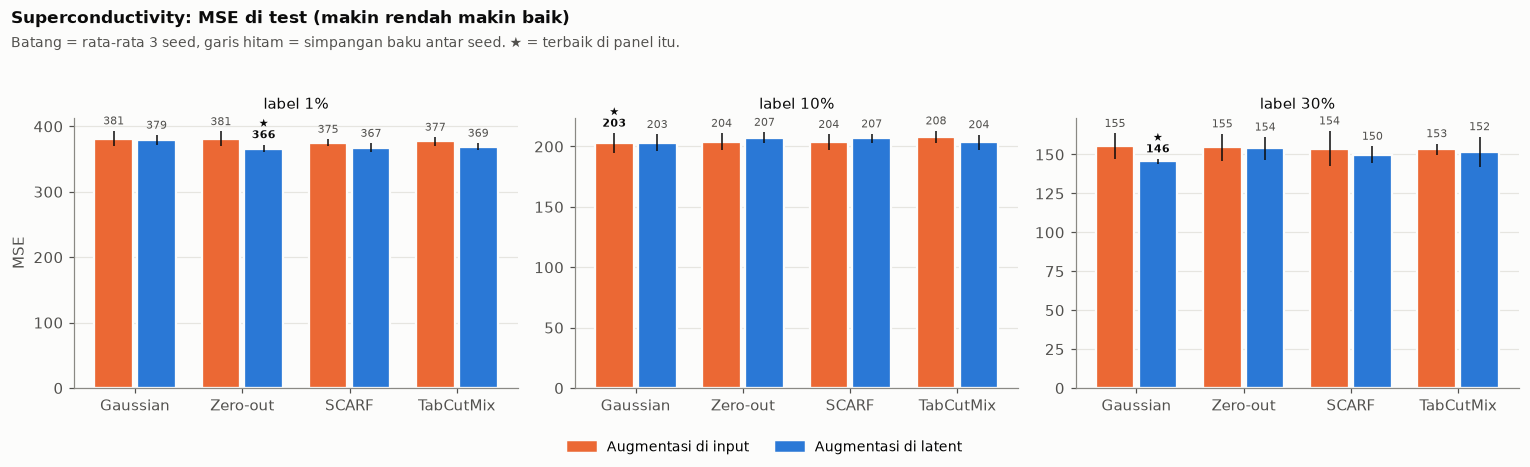

In [2]:
OP4 = {'gaussian': 'Gaussian', 'zero_out': 'Zero-out', 'scarf': 'SCARF', 'tabcutmix': 'TabCutMix'}
POS = {'input': ('Augmentasi di input', '#eb6834'), 'latent': ('Augmentasi di latent', '#2a78d6')}
DATASET = {'nhanes': ('NHANES', 'QWK', 'makin tinggi makin baik', '{:.3f}'),
           'pendigits': ('Pen Digits', 'Macro F1', 'makin tinggi makin baik', '{:.3f}'),
           'superconductivity': ('Superconductivity', 'MSE', 'makin rendah makin baik', '{:.0f}')}
NAMES = [f'{pos}_{op}' for op in OP4 for pos in POS]
stats = df[df.name.isin(NAMES)].groupby(['name', 'dataset', 'label'])['test'].agg(['mean', 'std'])
SIGN = {'nhanes': 1, 'pendigits': 1, 'superconductivity': -1}  # MSE: makin kecil makin baik

def label_bar(ax, x, m, s, fmt, best, size=7.5):
    # angka di atas batang; yang terbaik di panel itu ditebalkan dan diberi bintang
    ax.annotate(('★\n' if best else '') + fmt.format(m), (x, m + s), xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=size, linespacing=1.0,
                color=INK if best else '#52514e', fontweight='bold' if best else 'normal')

for dataset, (title, metric, hint, fmt) in DATASET.items():
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
    for ax, label in zip(axes, (1, 10, 30)):
        means = {(op, pos): stats.loc[(f'{pos}_{op}', dataset, label), 'mean'] for op in OP4 for pos in POS}
        best = max(means, key=lambda k: SIGN[dataset] * means[k])
        for i, op in enumerate(OP4):
            for j, (pos, (_, color)) in enumerate(POS.items()):
                m, s = stats.loc[(f'{pos}_{op}', dataset, label)]
                x = i + (j - 0.5) * 0.4
                ax.bar(x, m, 0.36, color=color, edgecolor='#fcfcfb', linewidth=1.5, zorder=2)
                ax.errorbar(x, m, s, fmt='none', ecolor=INK, elinewidth=1, capsize=0, zorder=4)
                label_bar(ax, x, m, s, fmt, (op, pos) == best)
        ax.set_xticks(range(4), OP4.values()); ax.set_title(f'label {label}%', fontsize=10, color=INK)
        ax.set_ylim(bottom=0); ax.margins(y=0.2); ax.grid(axis='x', visible=False)
    axes[0].set_ylabel(metric)
    fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for _, c in POS.values()], [l for l, _ in POS.values()],
               loc='lower center', ncol=2, frameon=False, fontsize=9)
    fig.suptitle(f'{title}: {metric} di test ({hint})', x=0.01, ha='left', fontsize=11, fontweight='bold', color=INK)
    fig.text(0.01, 0.9, 'Batang = rata-rata 3 seed, garis hitam = simpangan baku antar seed. ★ = terbaik di panel itu.', fontsize=9, color='#52514e')
    plt.tight_layout(rect=[0, 0.07, 1, 0.9]); plt.show()

In [3]:
# Angka yang sama dengan gambar di atas
df[df.name.isin(NAMES)].pivot_table(index=['dataset', 'label'], columns='name', values='test')[NAMES].round(3)

name                     input_gaussian  latent_gaussian  input_zero_out  \
dataset           label                                                    
nhanes            1               0.209            0.234           0.253   
                  10              0.260            0.261           0.231   
                  30              0.314            0.306           0.318   
pendigits         1               0.868            0.880           0.880   
                  10              0.953            0.948           0.948   
                  30              0.976            0.975           0.969   
superconductivity 1             381.368          379.421         381.003   
                  10            202.909          202.998         203.918   
                  30            155.406          145.730         154.672   

name                     latent_zero_out  input_scarf  latent_scarf  \
dataset           label                                               
nhanes            1                0.234        0.241         0.241   
                  10               0.261        0.242         0.260   
                  30               0.310        0.309         0.309   
pendigits         1                0.881        0.839         0.886   
                  10               0.951        0.952         0.950   
                  30               0.973        0.968         0.971   
superconductivity 1              366.146      375.028       367.334   
                  10             207.417      203.738       206.677   
                  30             153.884      153.771       149.875   

name                     input_tabcutmix  latent_tabcutmix  
dataset           label                                     
nhanes            1                0.223             0.240  
                  10               0.256             0.256  
                  30               0.305             0.314  
pendigits         1                0.855             0.874  
                  10               0.941             0.950  
                  30               0.971             0.972  
superconductivity 1              377.161           369.174  
                  10             207.898           203.588  
                  30             153.335           151.793

## Hasil utama (augmentasi di latent saja)

Gambar yang sama, hanya untuk augmentasi di latent. Weak = tidak diubah, strong = 0,5.

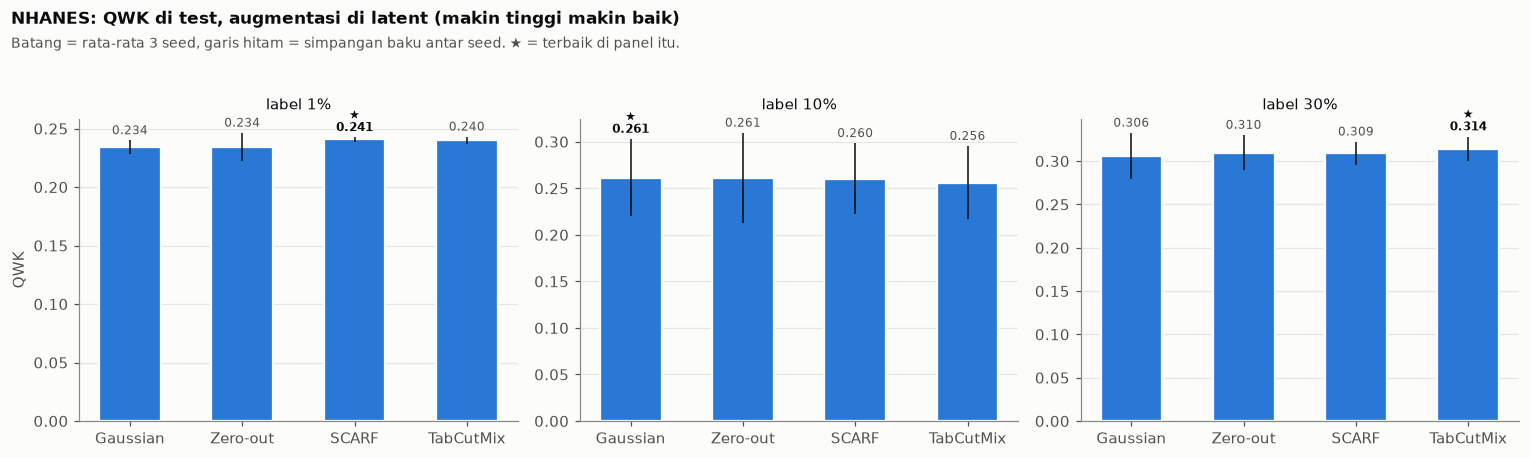

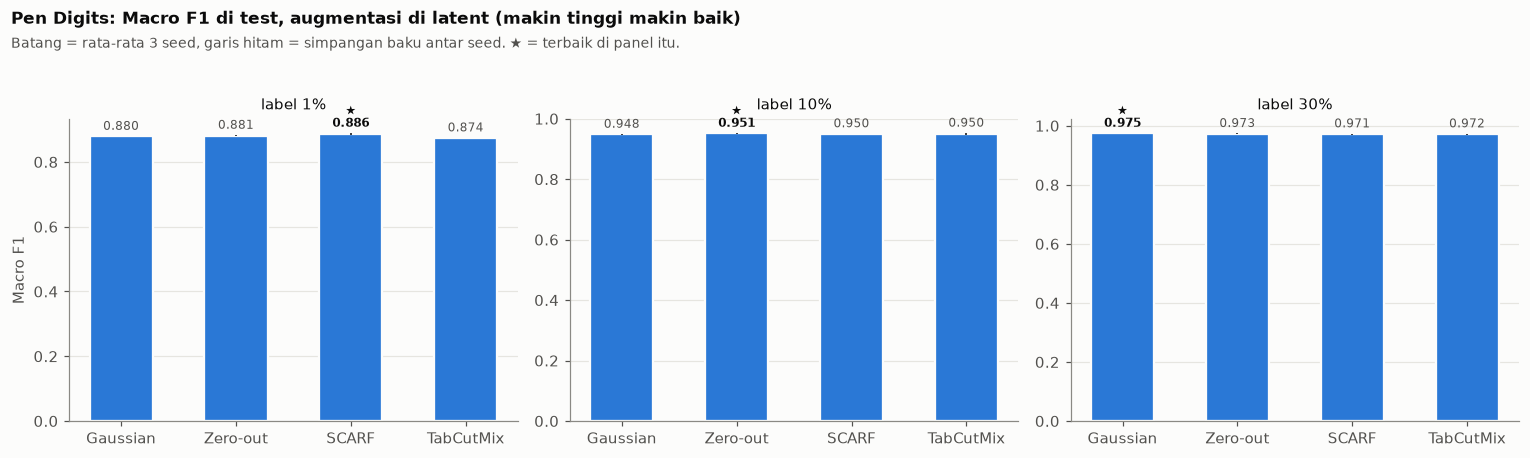

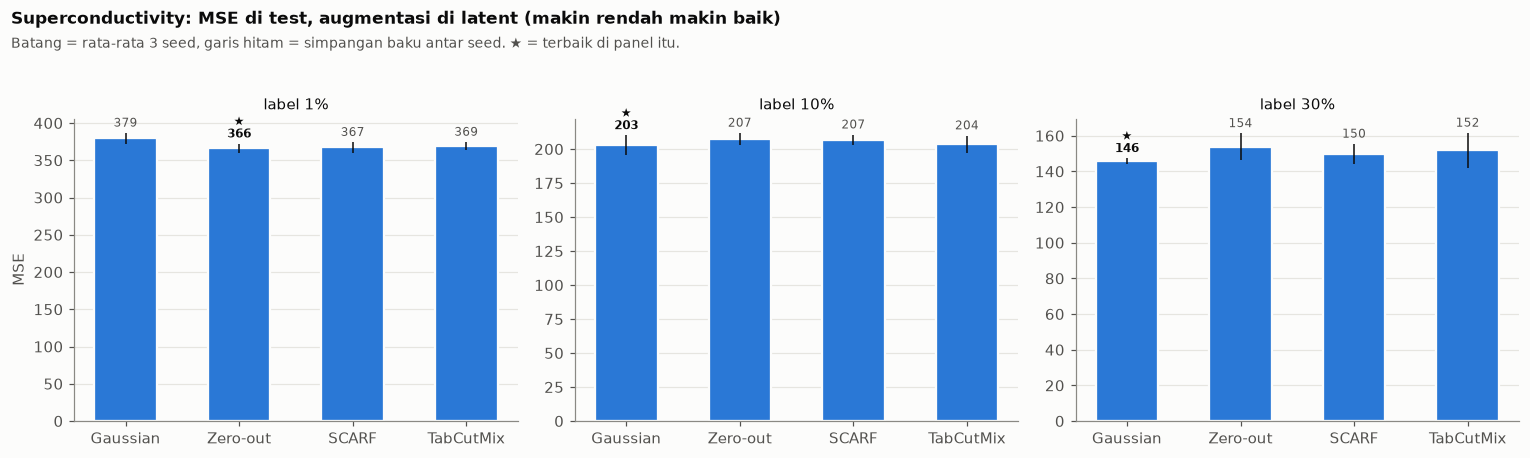

In [4]:
LAT = [f'latent_{op}' for op in OP4]
lat_stats = df[df.name.isin(LAT)].groupby(['name', 'dataset', 'label'])['test'].agg(['mean', 'std'])

for dataset, (title, metric, hint, fmt) in DATASET.items():
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
    for ax, label in zip(axes, (1, 10, 30)):
        means = {op: lat_stats.loc[(f'latent_{op}', dataset, label), 'mean'] for op in OP4}
        best = max(means, key=lambda k: SIGN[dataset] * means[k])
        for i, op in enumerate(OP4):
            m, s = lat_stats.loc[(f'latent_{op}', dataset, label)]
            ax.bar(i, m, 0.55, color='#2a78d6', edgecolor='#fcfcfb', linewidth=1.5, zorder=2)
            ax.errorbar(i, m, s, fmt='none', ecolor=INK, elinewidth=1, capsize=0, zorder=4)
            label_bar(ax, i, m, s, fmt, op == best, size=8)
        ax.set_xticks(range(4), OP4.values()); ax.set_title(f'label {label}%', fontsize=10, color=INK)
        ax.set_ylim(bottom=0); ax.margins(y=0.2); ax.grid(axis='x', visible=False)
    axes[0].set_ylabel(metric)
    fig.suptitle(f'{title}: {metric} di test, augmentasi di latent ({hint})', x=0.01, ha='left',
                 fontsize=11, fontweight='bold', color=INK)
    fig.text(0.01, 0.9, 'Batang = rata-rata 3 seed, garis hitam = simpangan baku antar seed. ★ = terbaik di panel itu.', fontsize=9, color='#52514e')
    plt.tight_layout(rect=[0, 0, 1, 0.9]); plt.show()

In [5]:
# Angka yang sama dengan gambar di atas
df[df.name.isin(LAT)].pivot_table(index=['dataset', 'label'], columns='name', values='test')[LAT].round(3)

name                     latent_gaussian  latent_zero_out  latent_scarf  \
dataset           label                                                   
nhanes            1                0.234            0.234         0.241   
                  10               0.261            0.261         0.260   
                  30               0.306            0.310         0.309   
pendigits         1                0.880            0.881         0.886   
                  10               0.948            0.951         0.950   
                  30               0.975            0.973         0.971   
superconductivity 1              379.421          366.146       367.334   
                  10             202.998          207.417       206.677   
                  30             145.730          153.884       149.875   

name                     latent_tabcutmix  
dataset           label                    
nhanes            1                 0.240  
                  10                0.256  
                  30                0.314  
pendigits         1                 0.874  
                  10                0.950  
                  30                0.972  
superconductivity 1               369.174  
                  10              203.588  
                  30              151.793

## 1. Arsitektur

Loop RankUp tidak diubah. Gangguan hanya dipasang di output backbone (hook), dan hanya untuk data unlabeled saat training.

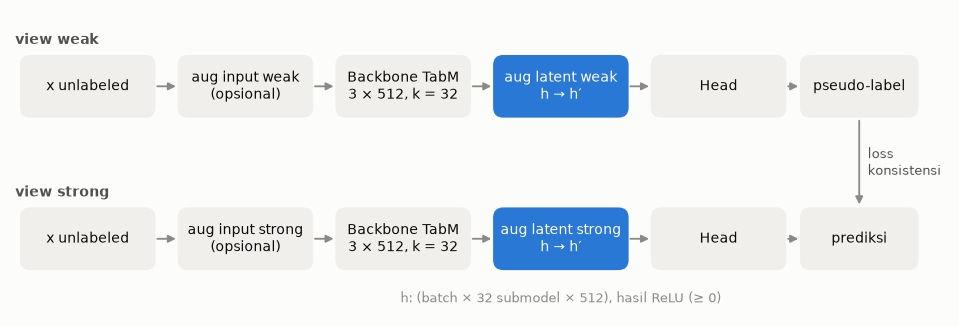

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.set_xlim(0, 11); ax.set_ylim(0, 3.6); ax.axis('off')

def box(x, y, text, color='#f0efec', ink=INK, w=1.55, h=0.7):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle='round,pad=0.02,rounding_size=0.12',
                                fc=color, ec='none'))
    ax.text(x, y, text, ha='center', va='center', fontsize=9, color=ink)

def arrow(x1, y1, x2, y2, **kw):
    ax.annotate('', (x2, y2), (x1, y1), arrowprops=dict(arrowstyle='-|>', color=MUTED, lw=1.2, **kw))

xs = [0.9, 2.75, 4.6, 6.45, 8.3]
for y, role, out in ((2.7, 'weak', 'pseudo-label'), (0.9, 'strong', 'prediksi')):
    box(xs[0], y, 'x unlabeled')
    box(xs[1], y, f'aug input {role}\n(opsional)')
    box(xs[2], y, 'Backbone TabM\n3 × 512, k = 32')
    box(xs[3], y, f'aug latent {role}\nh → h′', color='#2a78d6', ink='white')
    box(xs[4], y, 'Head')
    box(9.95, y, out, w=1.35)
    for a, b in zip(xs, xs[1:] + [9.95]):
        arrow(a + 0.78, y, b - (0.68 if b == 9.95 else 0.78), y)
    ax.text(0.05, y + 0.5, f'view {role}', fontsize=9, color='#52514e', fontweight='bold')
arrow(9.95, 2.33, 9.95, 1.27)
ax.text(10.05, 1.8, 'loss\nkonsistensi', fontsize=8.5, color='#52514e', va='center')
ax.text(xs[3], 0.15, 'h: (batch × 32 submodel × 512), hasil ReLU (≥ 0)', ha='center', fontsize=8.5, color=MUTED)
plt.show()

## 2. Peringkat semua konfigurasi

Rata-rata peringkat di 27 blok (dataset × label × seed), dihitung dari **validation**. 1 = terbaik.

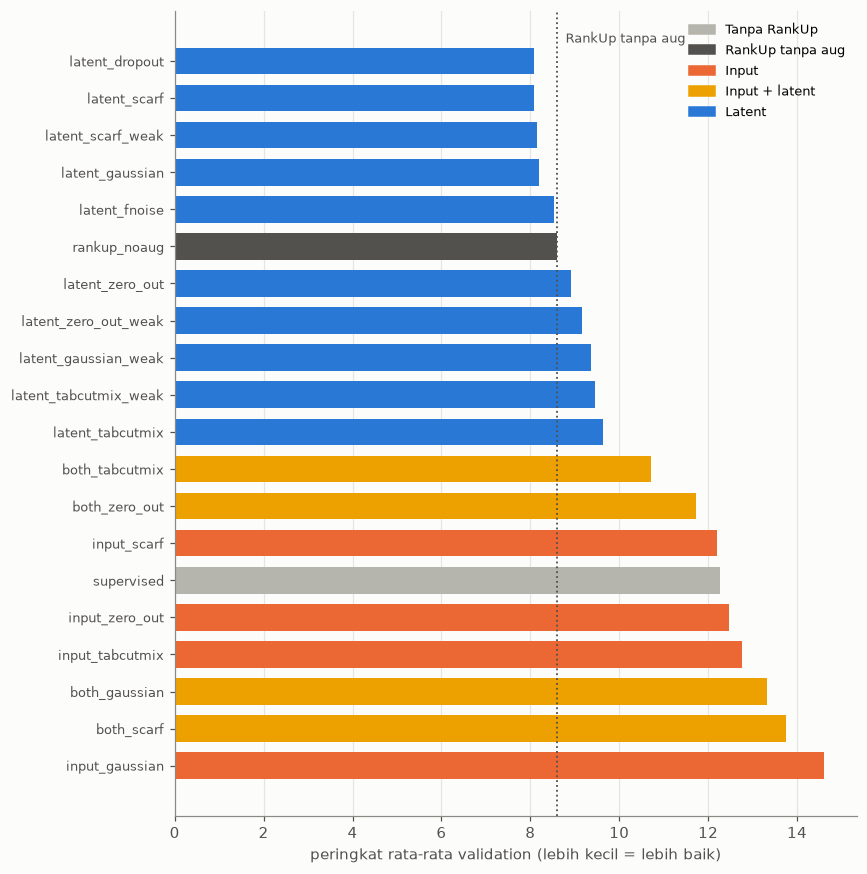

In [7]:
order = ranks.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 9.5))
ax.barh(order.index, order.values, color=[GROUP_COLOR[group(n)] for n in order.index], height=0.72)
ax.axvline(ranks['rankup_noaug'], color='#52514e', ls=':', lw=1.2)
ax.text(ranks['rankup_noaug'] + 0.2, len(order) - 0.4, 'RankUp tanpa aug', fontsize=8.5, color='#52514e', va='center')
ax.set_xlabel('peringkat rata-rata validation (lebih kecil = lebih baik)')
ax.grid(axis='y', visible=False); ax.tick_params(axis='y', labelsize=8.5)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLOR.values()]
ax.legend(handles, GROUP_COLOR.keys(), loc='upper right', fontsize=8.5, frameon=False)
plt.show()

## 3. Skor test per dataset

Rata-rata ± std dari 3 seed untuk konfigurasi kunci.

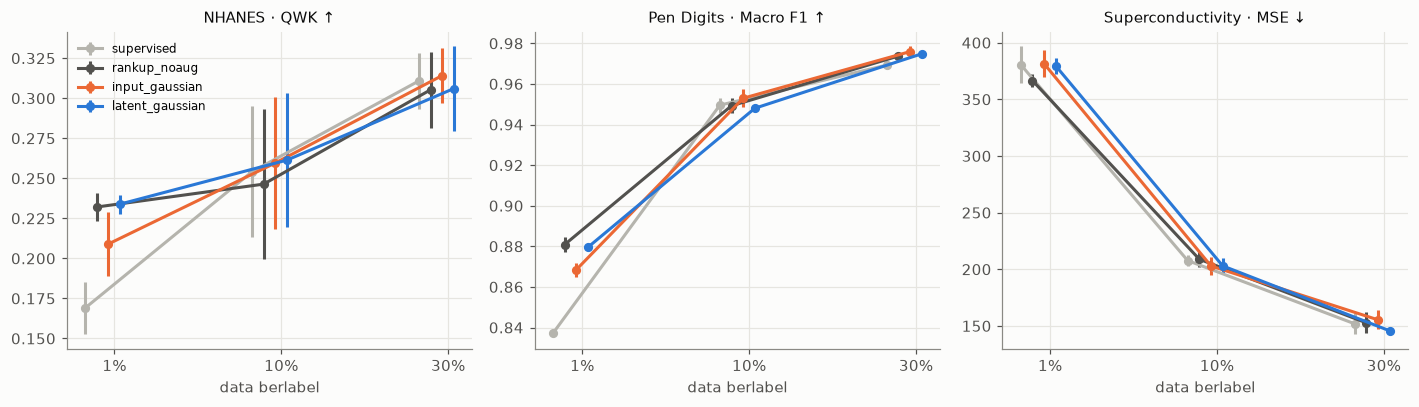

In [8]:
KEY = {'supervised': 'Tanpa RankUp', 'rankup_noaug': 'RankUp tanpa aug', 'input_gaussian': 'Input',
       'latent_gaussian': 'Latent'}
METRIC = {'nhanes': 'NHANES · QWK ↑', 'pendigits': 'Pen Digits · Macro F1 ↑', 'superconductivity': 'Superconductivity · MSE ↓'}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (dataset, title) in zip(axes, METRIC.items()):
    for i, (name, grp) in enumerate(KEY.items()):
        s = df[(df.dataset == dataset) & (df.name == name)].groupby('label')['test'].agg(['mean', 'std'])
        x = np.arange(len(s)) + (i - 2.5) * 0.07  # geser sedikit agar error bar tidak bertumpuk
        ax.errorbar(x, s['mean'], s['std'], color=GROUP_COLOR[grp], marker='o', ms=5, lw=2, capsize=0,
                    label=f'{name}')
    ax.set_xticks(range(3), ['1%', '10%', '30%']); ax.set_title(title, fontsize=10, color=INK)
    ax.set_xlabel('data berlabel')
axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## 4. Proses training

Rata-rata semua konfigurasi RankUp. Early stopping: patience 15 epoch, ambang pseudo-label 0,95.

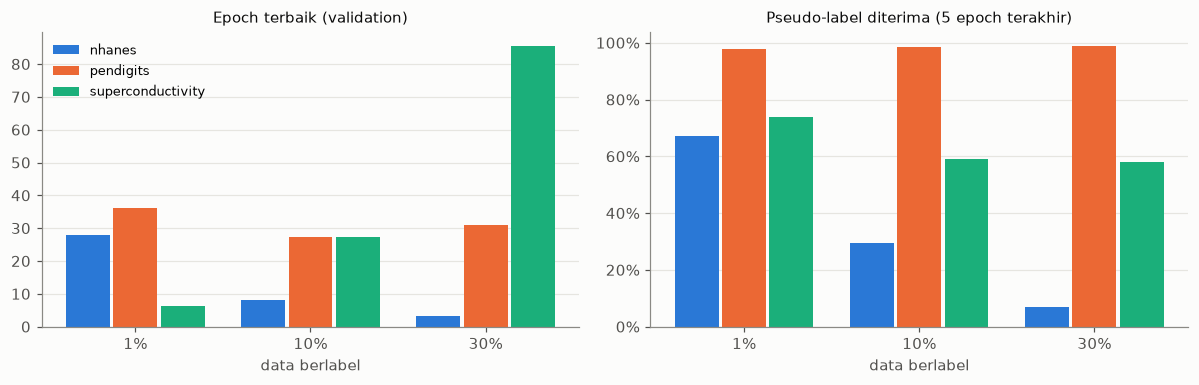

In [9]:
DS_COLOR = {'nhanes': '#2a78d6', 'pendigits': '#eb6834', 'superconductivity': '#1baf7a'}
import pandas as pd
raw = pd.read_json(HASIL / 'results.jsonl', lines=True)  # load() tidak membawa kolom proses training
semi = raw[raw.name != 'supervised'].rename(columns={'label_percent': 'label', 'accept_rate_last5': 'accept_rate'})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (col, title) in zip(axes, (('best_epoch', 'Epoch terbaik (validation)'),
                                   ('accept_rate', 'Pseudo-label diterima (5 epoch terakhir)'))):
    for i, (dataset, color) in enumerate(DS_COLOR.items()):
        v = semi[semi.dataset == dataset].groupby('label')[col].mean()
        ax.bar(np.arange(3) + (i - 1) * 0.27, v.values, width=0.25, color=color, label=dataset)
    ax.set_xticks(range(3), ['1%', '10%', '30%']); ax.set_title(title, fontsize=10, color=INK)
    ax.set_xlabel('data berlabel'); ax.grid(axis='x', visible=False)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[0].legend(fontsize=8.5, frameon=False)
plt.tight_layout(); plt.show()

## 5. Perbandingan dengan eksperimen sebelumnya (augmentasi di input)

| Nama | Augmentasi di | Strength | Seed |
|---|---|---|---|
| **Aug. input + Optuna** | data input | dicari otomatis oleh Optuna (40 trial) | 5 |
| **Aug. input** | data input | tetap (strong 0,5), tanpa tuning | 3 |
| **Aug. latent** | output encoder (eksperimen ini) | tetap, tanpa tuning | 3 |

Titik = rata-rata test, garis = std antar seed.

In [10]:
optuna = pd.read_csv(HASIL / 'pembanding' / 'ringkasan-5seed-40trial.csv')
optuna = optuna.rename(columns={'label_percent': 'label', 'mean': 'test_mean', 'std': 'test_std', 'validation_mean': 'val_mean'})
optuna['name'] = 'optuna_' + optuna['method']
cur = (df.groupby(['name', 'dataset', 'label'])
         .agg(test_mean=('test', 'mean'), test_std=('test', 'std'), val_mean=('val', 'mean')).reset_index())
allr = pd.concat([cur, optuna[cur.columns]], ignore_index=True)

APPROACH = {'Tanpa RankUp': '#b5b4ad', 'RankUp tanpa aug': '#52514e', 'Aug. input + Optuna': '#eda100',
            'Aug. input': '#eb6834', 'Aug. latent': '#2a78d6'}
def approach(name):
    if name.startswith('optuna_'): return 'Aug. input + Optuna'
    if name.startswith('input_'): return 'Aug. input'
    if name.startswith('latent_'): return 'Aug. latent'
    return {'supervised': 'Tanpa RankUp', 'rankup_noaug': 'RankUp tanpa aug'}.get(name)  # both_* tidak dipakai

allr['approach'] = allr['name'].map(approach)
allr = allr.dropna(subset=['approach']).reset_index(drop=True)
SIGN = {'nhanes': 1, 'pendigits': 1, 'superconductivity': -1}
allr['val_good'] = allr['val_mean'] * allr['dataset'].map(SIGN)

### 5a. Terbaik per pendekatan

Untuk tiap pendekatan, dipilih konfigurasi dengan **validation** terbaik, lalu ditampilkan skor test-nya.

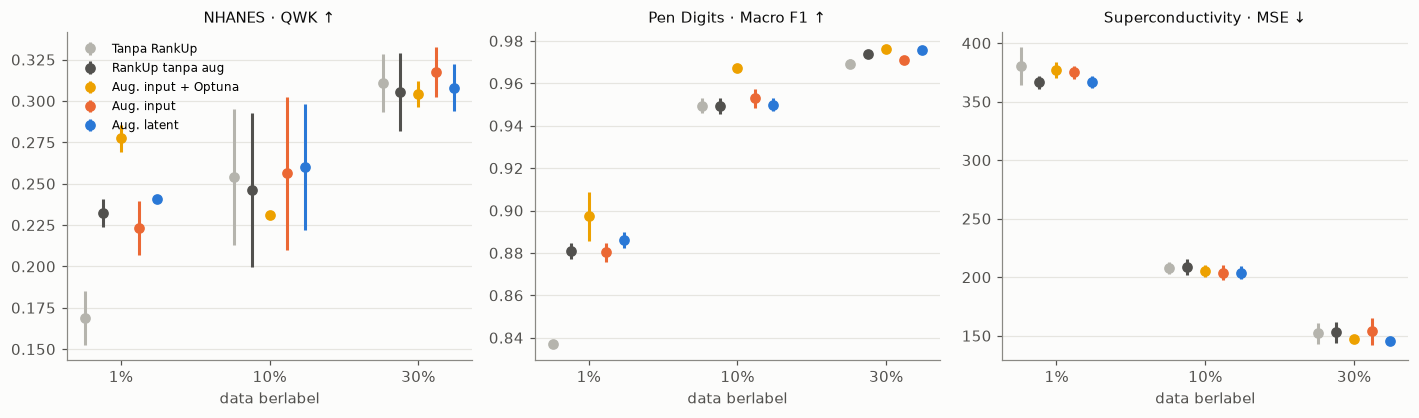

approach                Tanpa RankUp RankUp tanpa aug    Aug. input + Optuna  \
dataset           label                                                        
nhanes            1       supervised     rankup_noaug   optuna_range_limited   
                  10      supervised     rankup_noaug       optuna_tabcutmix   
                  30      supervised     rankup_noaug           optuna_scarf   
pendigits         1       supervised     rankup_noaug       optuna_tabcutmix   
                  10      supervised     rankup_noaug       optuna_tabcutmix   
                  30      supervised     rankup_noaug        optuna_gaussian   
superconductivity 1       supervised     rankup_noaug           optuna_scarf   
                  10      supervised     rankup_noaug  optuna_tabcutmix_plus   
                  30      supervised     rankup_noaug  optuna_tabcutmix_plus   

approach                      Aug. input           Aug. latent  
dataset           label                                         
nhanes            1      input_tabcutmix          latent_scarf  
                  10     input_tabcutmix          latent_scarf  
                  30      input_zero_out  latent_zero_out_weak  
pendigits         1       input_zero_out          latent_scarf  
                  10      input_gaussian      latent_tabcutmix  
                  30     input_tabcutmix         latent_fnoise  
superconductivity 1          input_scarf     latent_scarf_weak  
                  10         input_scarf        latent_dropout  
                  30         input_scarf       latent_gaussian

In [11]:
best = allr.loc[allr.groupby(['approach', 'dataset', 'label'])['val_good'].idxmax()]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (dataset, title) in zip(axes, METRIC.items()):
    for i, (grp, color) in enumerate(APPROACH.items()):
        s = best[(best.dataset == dataset) & (best.approach == grp)].sort_values('label')
        x = np.arange(len(s)) + (i - 2) * 0.12
        ax.errorbar(x, s['test_mean'], s['test_std'], color=color, marker='o', ms=6, lw=0, elinewidth=2, label=grp)
    ax.set_xticks(range(3), ['1%', '10%', '30%']); ax.set_title(title, fontsize=10, color=INK)
    ax.set_xlabel('data berlabel'); ax.grid(axis='x', visible=False)
axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

table = best.pivot_table(index=['dataset', 'label'], columns='approach', values='name', aggfunc='first')
table[[c for c in APPROACH if c in table]]  # konfigurasi yang terpilih

### 5b. Per operator: input vs latent

Operator yang sama di dua posisi. Garis horizontal: RankUp tanpa augmentasi (titik-titik) dan tanpa RankUp (putus-putus).

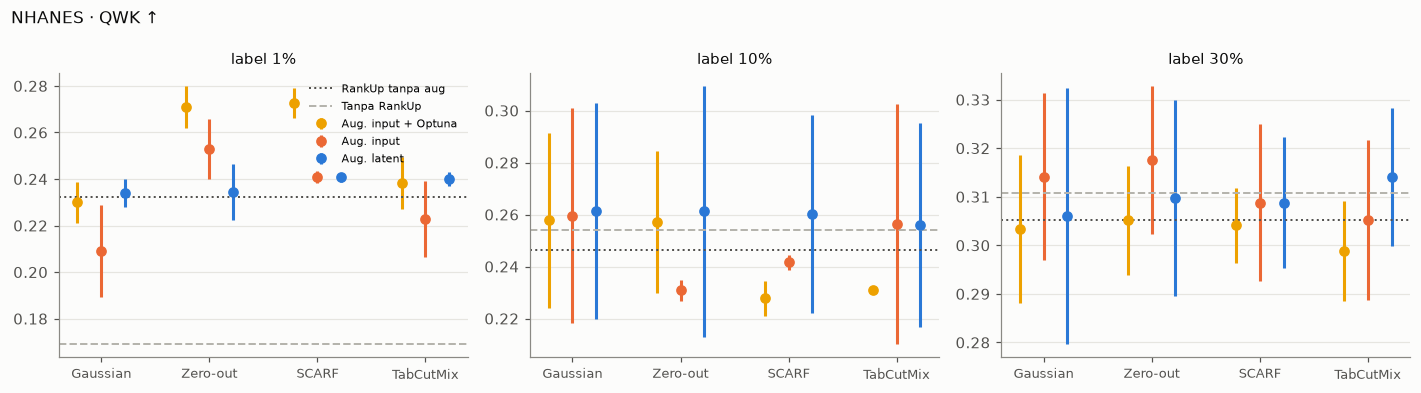

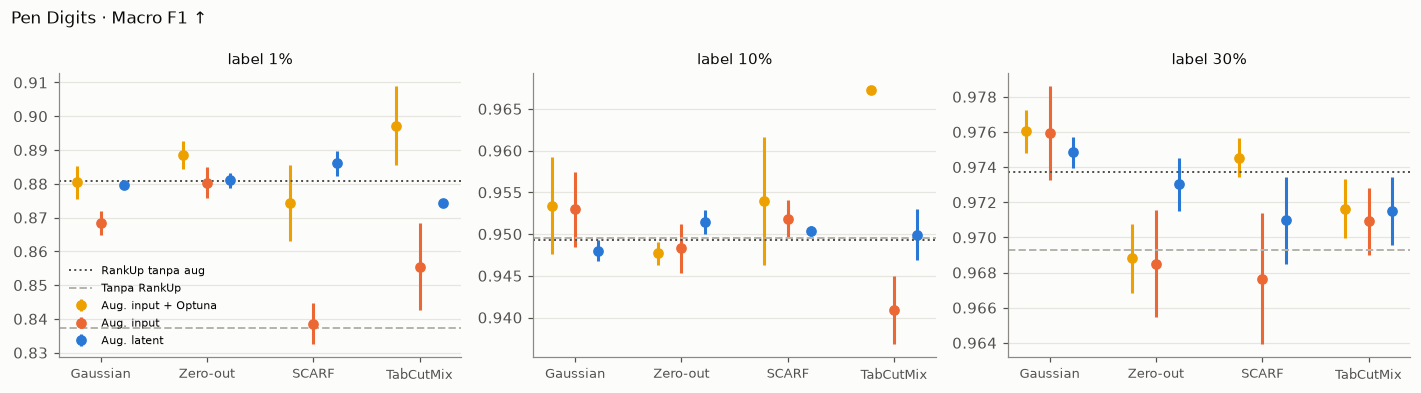

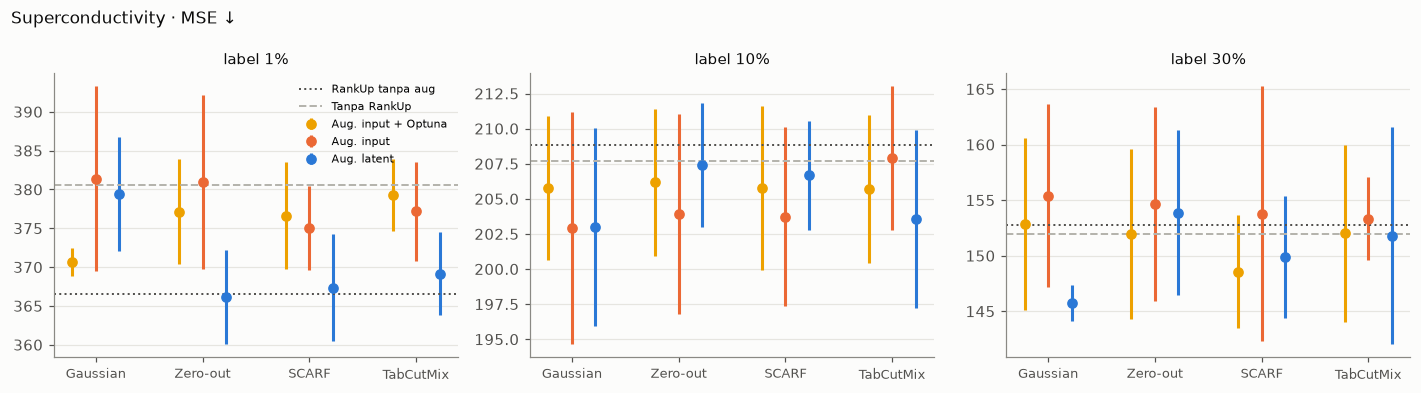

In [12]:
OPS = {'gaussian': 'Gaussian', 'zero_out': 'Zero-out', 'scarf': 'SCARF', 'tabcutmix': 'TabCutMix'}
SERIES = {'Aug. input + Optuna': 'optuna_{}', 'Aug. input': 'input_{}', 'Aug. latent': 'latent_{}'}
look = allr.set_index(['name', 'dataset', 'label'])

def cell(name, dataset, label):
    key = (name, dataset, label)
    return look.loc[key, ['test_mean', 'test_std']] if key in look.index else None

for dataset, title in METRIC.items():
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
    fig.suptitle(title, fontsize=11, color=INK, x=0.01, ha='left')
    for ax, label in zip(axes, (1, 10, 30)):
        for i, (grp, pattern) in enumerate(SERIES.items()):
            for j, op in enumerate(OPS):
                name = pattern.format(op)
                v = cell(name, dataset, label)
                if v is None:
                    continue
                ax.errorbar(j + (i - 1) * 0.22, v['test_mean'], v['test_std'], color=APPROACH[grp], marker='o',
                            ms=6, lw=0, elinewidth=2, label=grp if j == 0 else None)
        for ref, ls in (('rankup_noaug', ':'), ('supervised', '--')):
            ax.axhline(look.loc[(ref, dataset, label), 'test_mean'], color=APPROACH[approach(ref)], ls=ls, lw=1.3,
                       label=approach(ref))
        ax.set_xticks(range(len(OPS)), OPS.values(), fontsize=8.5); ax.set_title(f'label {label}%', fontsize=10, color=INK)
        ax.grid(axis='x', visible=False)
    axes[0].legend(fontsize=7.5, frameon=False)
    plt.tight_layout(); plt.show()

## Ringkasan

- RankUp membantu terutama di label 1% (NHANES, Pen Digits).
- Augmentasi di input cenderung merugikan; augmentasi di latent setara dengan RankUp tanpa augmentasi.
- NHANES 10–30% berhenti di epoch awal dan pseudo-label jarang lolos, jadi hasilnya didominasi noise.
- Dibanding eksperimen sebelumnya (tabel 5a): aug. input + Optuna terbaik di 3 dari 9 kondisi, aug. latent di 3, sisanya
  tersebar. Tidak ada pendekatan yang konsisten terbaik. Aug. input + Optuna di-tuning dan memakai 5 seed; aug. latent belum.
- Batasan: 3 seed, satu split data.